In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load data
df = pd.read_csv("/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/merged_aqi_corrected_cleaned.csv")

# Encode labels
label_enc = LabelEncoder()
df['AQI_Label'] = label_enc.fit_transform(df['AQI_Category'])

# Define features and target
features = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
X = df[features]
y = df['AQI_Label']


In [ ]:
# ============================================================
# STEP 1: Train-Test Split (Before Normalization)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ============================================================
# STEP 2: Normalize Features (Avoid Data Leakage)
# ============================================================

scaler = StandardScaler()

# Fit scaler only on training data
X_train = scaler.fit_transform(X_train)

# Transform test data using training scaler
X_test = scaler.transform(X_test)

# ============================================================
# STEP 3: Define Individual Models
# ============================================================

xgb_model = XGBClassifier(
    use_label_encoder=False,
        eval_metric='mlogloss',
        random_state=42,
)

bagging_model = BaggingClassifier(
    max_samples=0.8,
        max_features=0.8,
        random_state=42,
)

rf_model = RandomForestClassifier(
    max_depth=6,
        max_features=0.8,
        random_state=42,)

# svm_model = SVC(
#     probability=True,
#     random_state=42
# )

# ============================================================
# STEP 4: Create Voting Ensemble
# ============================================================

voting_clf = VotingClassifier(
    estimators=[
        ('xgb', xgb_model),
        ('bagging', bagging_model),
        ('rf', rf_model),
        # ('svm', svm_model)
    ],
    voting='soft'
)

# ============================================================
# STEP 5: Train Ensemble
# ============================================================

voting_clf.fit(X_train, y_train)

# ============================================================
# STEP 6: Predict
# ============================================================

y_pred = voting_clf.predict(X_test)

# ============================================================
# STEP 7: Evaluation
# ============================================================

print("=== Voting Ensemble Classification Report ===")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_enc.classes_,
        digits=4,
        zero_division=0
    )
)

print("Accuracy:", accuracy_score(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [21:45:19] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== Voting Ensemble Classification Report ===
              precision    recall  f1-score   support

        Good     0.9983    0.9987    0.9985      2360
    Moderate     0.9997    0.9997    0.9997     34189
        Poor     0.9993    0.9969    0.9981      2880
Satisfactory     0.9983    0.9991    0.9987      7453
      Severe     0.9994    0.9994    0.9994      1768
   Very Poor     0.9998    0.9995    0.9996      5616

    accuracy                         0.9994     54266
   macro avg     0.9991    0.9989    0.9990     54266
weighted avg     0.9994    0.9994    0.9994     54266

Accuracy: 0.9994103121659971


In [ ]:
import time

start = time.perf_counter()
voting_clf.fit(X_train, y_train)
training_time = time.perf_counter() - start

start = time.perf_counter()
y_pred = voting_clf.predict(X_test)
inference_time = time.perf_counter() - start

print(f"Training Time: {training_time:.4f} seconds")
print(f"Inference Time: {inference_time:.4f} seconds")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [21:45:59] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Training Time: 35.8221 seconds
Inference Time: 0.3306 seconds


In [ ]:
# ============================================================
# STEP 8: MULTICLASS AVERAGE PRECISION (AP)
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------
# 1. Obtain predicted class probabilities
# ------------------------------------------------------------

y_proba = voting_clf.predict_proba(X_test)

# Use the exact class order of the trained voting classifier
classes = voting_clf.classes_

# ------------------------------------------------------------
# 2. Convert true labels to one-vs-rest format
# ------------------------------------------------------------

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

# ------------------------------------------------------------
# 3. Calculate AP for each AQI category
# ------------------------------------------------------------

ap_results = []

for i, class_id in enumerate(classes):

    class_ap = average_precision_score(
        y_test_bin[:, i],
        y_proba[:, i]
    )

    class_name = label_enc.inverse_transform(
        [int(class_id)]
    )[0]

    ap_results.append({
        "AQI Category": class_name,
        "Support": int(y_test_bin[:, i].sum()),
        "Average Precision": class_ap
    })

ap_df = pd.DataFrame(ap_results)

# ------------------------------------------------------------
# 4. Calculate Macro, Weighted, and Micro AP
# ------------------------------------------------------------

macro_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="macro"
)

weighted_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="weighted"
)

micro_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="micro"
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n=== CLASS-WISE AVERAGE PRECISION ===")

print(
    ap_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n=== OVERALL AP RESULTS ===")
print(f"Macro AP    : {macro_ap:.6f}")
print(f"Weighted AP : {weighted_ap:.6f}")
print(f"Micro AP    : {micro_ap:.6f}")

# ------------------------------------------------------------
# 6. Save results to Google Drive
# ------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/My work/Air Quality Project/"
    "Paper 1(External Data)/New"
)

os.makedirs(output_dir, exist_ok=True)

ap_df.to_csv(
    os.path.join(output_dir, "Voting_Ensemble_Classwise_AP.csv"),
    index=False
)

pd.DataFrame([{
    "Model": "Three-Model Soft-Voting Ensemble",
    "Macro_AP": macro_ap,
    "Weighted_AP": weighted_ap,
    "Micro_AP": micro_ap
}]).to_csv(
    os.path.join(output_dir, "Voting_Ensemble_Overall_AP.csv"),
    index=False
)

print(f"\nAP results saved successfully to:\n{output_dir}")


=== CLASS-WISE AVERAGE PRECISION ===
AQI Category  Support  Average Precision
        Good     2360           0.999966
    Moderate    34189           0.999999
        Poor     2880           0.998922
Satisfactory     7453           0.999984
      Severe     1768           0.999944
   Very Poor     5616           0.999914

=== OVERALL AP RESULTS ===
Macro AP    : 0.999788
Weighted AP : 0.999928
Micro AP    : 0.999974

AP results saved successfully to:
/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New


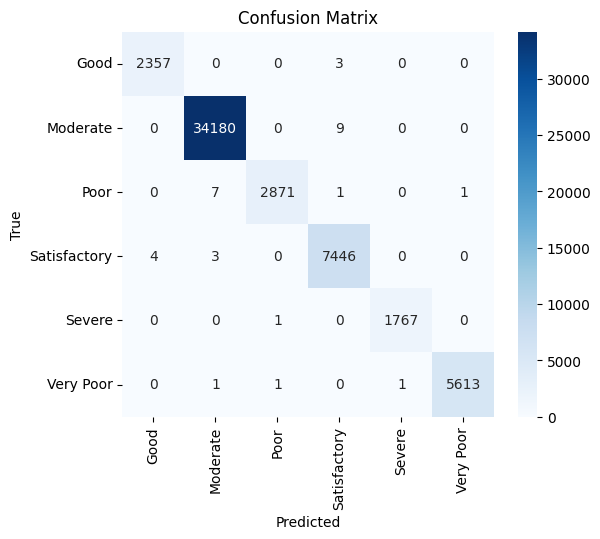

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns # Import seaborn

# Assuming y_test (true labels) and y_pred (predicted labels) are available from previous steps
# Assuming label_enc (LabelEncoder) is available to get class names

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Get the class names
class_names = label_enc.classes_
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=label_enc.classes_, yticklabels=label_enc.classes_, # Corrected variable name from 'le' to 'label_enc'
            cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# from sklearn.inspection import permutation_importance
# import matplotlib.pyplot as plt
# import pandas as pd
# # Run permutation importance on the test set
# result = permutation_importance(
#     voting_clf,
#     X_test,
#     y_test,
#     n_repeats=10,
#     random_state=42,
#     scoring='accuracy'  # You can also use 'f1_weighted', 'balanced_accuracy', etc.
# )
# # Convert results to a DataFrame
# importance_df = pd.DataFrame({
#     'feature': features,
#     'importance_mean': result.importances_mean,
#     'importance_std': result.importances_std
# }).sort_values(by='importance_mean', ascending=False)

# # Print top 10 features
# print("Top 10 important features:")
# print(importance_df.head(10))

# # Plot
# plt.figure(figsize=(10, 6))
# plt.barh(importance_df['feature'], importance_df['importance_mean'], xerr=importance_df['importance_std'])
# plt.xlabel("Mean Importance (Accuracy Drop)")
# plt.title("Permutation Feature Importance (VotingClassifier)")
# plt.gca().invert_yaxis()
# plt.grid(True)
# plt.tight_layout()
# plt.show()


In [ ]:
from scipy.stats import entropy
import numpy as np

# Get predicted probabilities for all classes
y_proba = voting_clf.predict_proba(X_test)  # Shape: [n_samples, n_classes]

# Compute predictive entropy for each sample
uncertainties = entropy(y_proba.T)  # Entropy over class probs (axis=1), shape: [n_samples]

# Show some stats
print("\n=== Uncertainty Analysis ===")
print(f"Mean entropy (uncertainty): {uncertainties.mean():.4f}")
print(f"Max entropy: {uncertainties.max():.4f}")
print(f"Min entropy: {uncertainties.min():.4f}")

# Optional: View most uncertain samples
top_k = 5
most_uncertain_idx = uncertainties.argsort()[-top_k:][::-1]

print(f"\nTop {top_k} most uncertain predictions:")
for i in most_uncertain_idx:
    print(f"Sample {i} - True: {label_enc.inverse_transform([y_test.iloc[i]])[0]}, "
          f"Predicted: {label_enc.inverse_transform([y_pred[i]])[0]}, "
          f"Entropy: {uncertainties[i]:.4f}")


=== Uncertainty Analysis ===
Mean entropy (uncertainty): 0.1589
Max entropy: 1.4600
Min entropy: 0.0000

Top 5 most uncertain predictions:
Sample 20726 - True: Very Poor, Predicted: Very Poor, Entropy: 1.4600
Sample 51172 - True: Severe, Predicted: Severe, Entropy: 1.4463
Sample 20308 - True: Very Poor, Predicted: Very Poor, Entropy: 1.4126
Sample 15097 - True: Very Poor, Predicted: Very Poor, Entropy: 1.4050
Sample 14987 - True: Very Poor, Predicted: Very Poor, Entropy: 1.3999


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(uncertainties, bins=50, color='orange', edgecolor='k')
plt.xlabel('Predictive Entropy')
plt.ylabel('Frequency')
plt.title('Distribution of Predictive Uncertainty')
plt.grid(True)
plt.tight_layout()
plt.show()


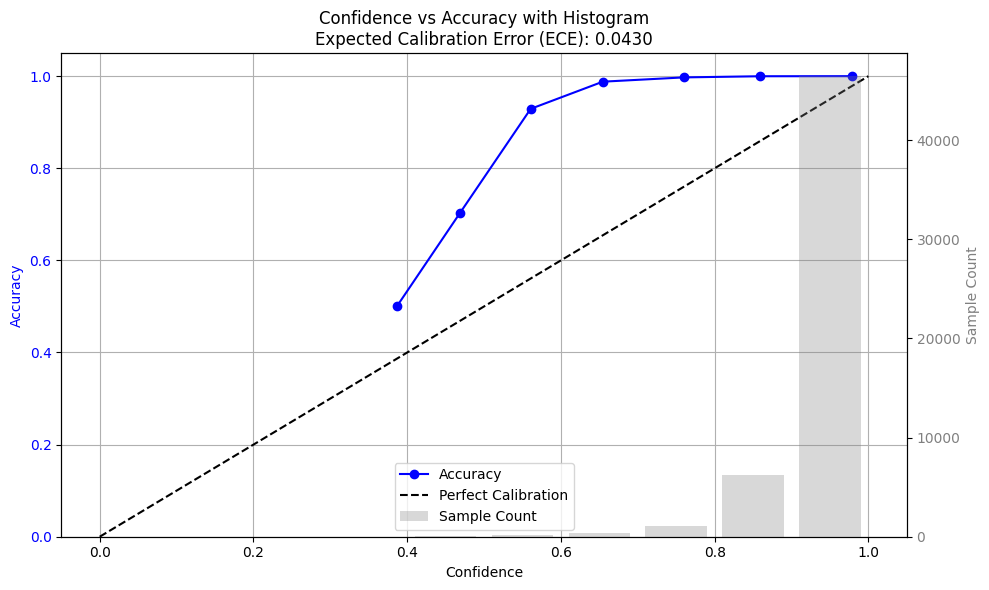

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- STEP 1: Calculate confidence and correctness ----------
y_proba = voting_clf.predict_proba(X_test)
confidences = np.max(y_proba, axis=1)
correct = (y_pred == y_test)

# ---------- STEP 2: Bin data ----------
bins = np.linspace(0.0, 1.0, 11)  # 10 bins: [0.0–0.1, 0.1–0.2, ..., 0.9–1.0]
bin_indices = np.digitize(confidences, bins) - 1

bin_accuracies = []
bin_confidence_means = []
bin_counts = []

ece = 0.0  # Expected Calibration Error

for i in range(len(bins) - 1):
    bin_mask = bin_indices == i
    bin_total = np.sum(bin_mask)

    if bin_total > 0:
        bin_correct = np.sum(correct[bin_mask])
        bin_accuracy = bin_correct / bin_total
        bin_avg_confidence = np.mean(confidences[bin_mask])

        bin_accuracies.append(bin_accuracy)
        bin_confidence_means.append(bin_avg_confidence)
        bin_counts.append(bin_total)

        # ---------- STEP 3: ECE calculation ----------
        ece += (bin_total / len(y_test)) * abs(bin_accuracy - bin_avg_confidence)
    else:
        bin_accuracies.append(np.nan)
        bin_confidence_means.append(np.nan)
        bin_counts.append(0)

# ---------- STEP 4: Plot ----------
fig, ax1 = plt.subplots(figsize=(10, 6))

# Accuracy line
ax1.plot(bin_confidence_means, bin_accuracies, marker='o', color='blue', label='Accuracy')
ax1.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
ax1.set_xlabel("Confidence")
ax1.set_ylabel("Accuracy", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(0.0, 1.05)
ax1.grid(True)

# Bar chart (histogram) on secondary y-axis
ax2 = ax1.twinx()
width = 0.08
bin_centers = (bins[:-1] + bins[1:]) / 2
ax2.bar(bin_centers, bin_counts, width=width, alpha=0.3, color='gray', label='Sample Count')
ax2.set_ylabel("Sample Count", color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

# Legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower center")

# Title with ECE
plt.title(f"Confidence vs Accuracy with Histogram\nExpected Calibration Error (ECE): {ece:.4f}")
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Get class labels
class_names = label_enc.classes_
n_classes = len(class_names)

# Binarize true labels (one-hot encoding)
y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))

# Predict class probabilities
y_score = voting_clf.predict_proba(X_test)

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], lw=2,
             label=f"Class {class_names[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Class-wise ROC Curves')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


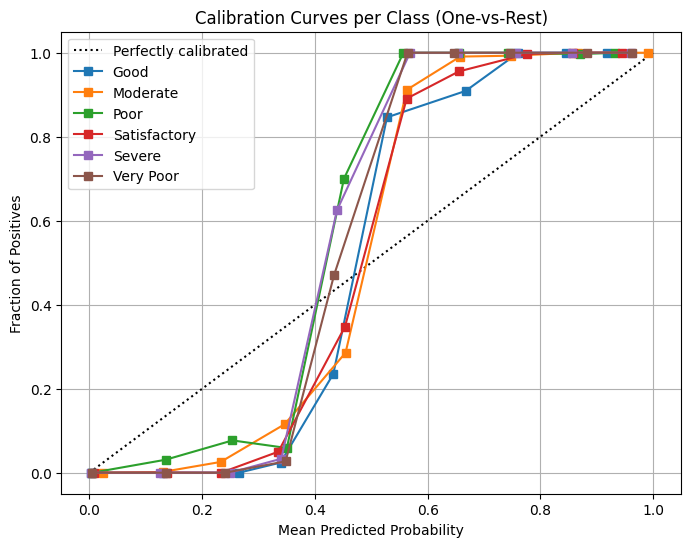

In [ ]:
from sklearn.calibration import CalibrationDisplay
from sklearn.preprocessing import label_binarize
import numpy as np # Import numpy if not already imported
import matplotlib.pyplot as plt # Import matplotlib


# Define the number of classes
num_classes = len(label_enc.classes_)

# Define y_test_bin by one-hot encoding y_test
y_test_bin = label_binarize(y_test, classes=np.arange(num_classes))

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(label_enc.classes_): # Corrected variable name from 'le' to 'label_enc'
    CalibrationDisplay.from_predictions(
        y_test_bin[:, i],
        y_score[:, i], # Corrected variable name from y_pred_prob to y_score
        n_bins=10,
        name=f'{class_name}',
        ax=plt.gca() # Plot all curves on the same axes
    )

plt.title('Calibration Curves per Class (One-vs-Rest)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

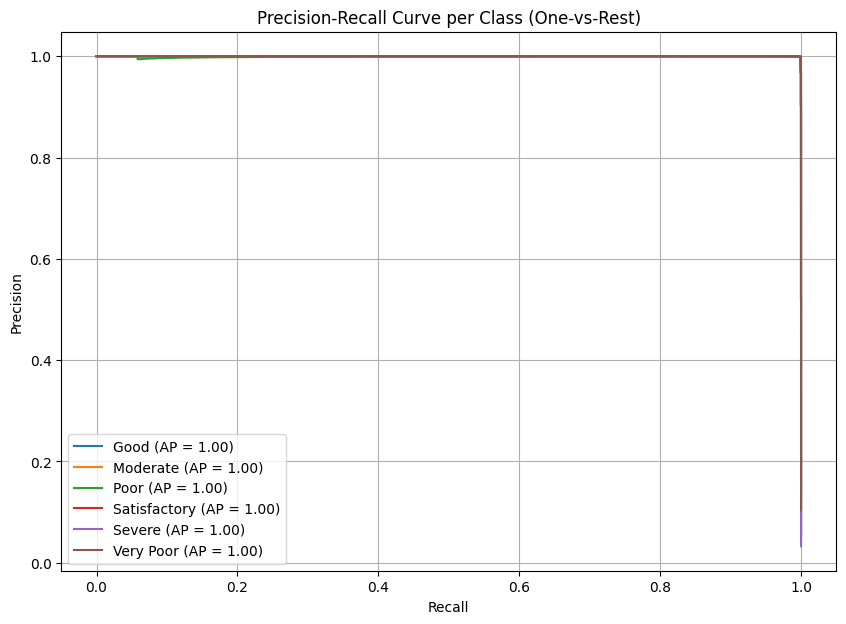

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(label_enc.classes_):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    ap_score = average_precision_score(y_test_bin[:, i], y_score[:, i])
    plt.plot(recall, precision, label=f'{class_name} (AP = {ap_score:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve per Class (One-vs-Rest)')
plt.legend()
plt.grid(True)
plt.show()

# Task
Apply LIME to explain the model's predictions.

## Install lime



In [ ]:
%pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=58fb09d70a42b168278e8c113eda6cd9c21d50e64df7ffbc8b77d01c8390995a
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


## Create a lime explainer




In [ ]:
from lime.lime_tabular import LimeTabularExplainer

explainer = LimeTabularExplainer(
    training_data=X_train,
    feature_names=features,
    class_names=class_names,
    mode='classification'
)

## Explain individual predictions



In [ ]:
# Select a few instances for explanation.
# Choosing some based on uncertainty and some randomly.
selected_indices = [
    most_uncertain_idx[0],  # Most uncertain
    most_uncertain_idx[1],  # Second most uncertain
    7932, # From the uncertainty analysis output
    2710, # From the uncertainty analysis output
    17864, # From the uncertainty analysis output
    np.random.randint(0, len(X_test)), # Random instance 1
    np.random.randint(0, len(X_test))  # Random instance 2
]

explanations = []
for i in selected_indices:
    instance = X_test[i]
    explanation = explainer.explain_instance(
        data_row=instance,
        predict_fn=voting_clf.predict_proba,
        num_features=len(features) # Include all features
    )
    explanations.append(explanation)

print(f"Generated {len(explanations)} explanations for selected instances.")

Generated 7 explanations for selected instances.


## Visualize explanations


In [ ]:
for i, explanation in enumerate(explanations):
    print(f"\nExplanation for selected instance {selected_indices[i]}:")
    fig = explanation.as_pyplot_figure()
    plt.tight_layout()
    plt.show()

In [ ]:
feature_names = features
X_train_np = np.array(X_train)

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

voting_clf_explainer = LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=feature_names,
    class_names=label_enc.classes_,
    mode='classification'
)

In [ ]:
from IPython.display import display, HTML
import random
import numpy as np
import pandas as pd
import json
import re

num_samples_per_class = 2
random.seed(42)

# ==========================================
# Function: Show all 6 classes in LIME HTML
# ==========================================

def show_all_classes_html(explanation):

    # Keep the original LIME HTML
    html_output = explanation.as_html()

    # Get all class names and probabilities
    class_names = [
        str(name)
        for name in explanation.class_names
    ]

    probabilities = np.asarray(
        explanation.predict_proba,
        dtype=float
    ).tolist()

    if len(class_names) != 6 or len(probabilities) != 6:
        raise ValueError(
            "Expected exactly six AQI classes."
        )


    custom_js = """
    var allClassNames = __CLASS_NAMES__;
    var allClassProbs = __PROBABILITIES__;

    var allClassData = allClassNames.map(
        function(name, i) {
            return {
                name: name,
                probability: allClassProbs[i]
            };
        }
    );

    // Highest probability first
    allClassData.sort(function(a, b) {
        return b.probability - a.probability;
    });

    // Use the original LIME probability SVG
    pp_svg
        .attr('width', 250)
        .attr('height', 180)
        .style('width', '250px')
        .style('height', '180px');

    // Chart title
    pp_svg.append('text')
        .attr('x', 0)
        .attr('y', 15)
        .style('font-size', '12px')
        .text('Prediction probabilities');

    allClassData.forEach(function(d, i) {

        var y = 28 + i * 24;

        // Class name
        pp_svg.append('text')
            .attr('x', 88)
            .attr('y', y + 12)
            .attr('text-anchor', 'end')
            .style('font-size', '11px')
            .text(d.name);

        // Bar outline
        pp_svg.append('rect')
            .attr('x', 94)
            .attr('y', y)
            .attr('width', 85)
            .attr('height', 16)
            .style('fill', 'white')
            .style('stroke', '#444')
            .style('stroke-width', '1px');

        // Probability bar
        pp_svg.append('rect')
            .attr('x', 94)
            .attr('y', y + 1)
            .attr('width', 83 * d.probability)
            .attr('height', 14)
            .style(
                'fill',
                i === 0 ? '#e15759' : '#4e9ac7'
            );

        // Probability value
        pp_svg.append('text')
            .attr('x', 185)
            .attr('y', y + 12)
            .style('font-size', '11px')
            .text(d.probability.toFixed(4));

    });
    """

    custom_js = custom_js.replace(
        "__CLASS_NAMES__",
        json.dumps(class_names)
    ).replace(
        "__PROBABILITIES__",
        json.dumps(probabilities)
    )

    # Replace only LIME's default probability chart
    pattern = (
        r"var\s+pp\s*=\s*new\s+lime\.PredictProba"
        r"\s*\(\s*pp_svg\s*,\s*\[[^\]]*\]\s*,"
        r"\s*\[[^\]]*\]\s*\)\s*;"
    )

    html_output, replacement_count = re.subn(
        pattern,
        lambda match: custom_js,
        html_output,
        count=1
    )

    if replacement_count != 1:
        raise RuntimeError(
            "LIME probability chart was not found. "
            "The installed LIME version may use "
            "a different HTML structure."
        )

    display(HTML(html_output))


# ==========================================
# 1. Select 2 samples from each AQI class
# ==========================================

iloc_class_indices = {}

for i_iloc in range(len(y_test)):

    label_value = int(y_test.iloc[i_iloc])
    class_name = label_enc.classes_[label_value]

    if class_name not in iloc_class_indices:
        iloc_class_indices[class_name] = []

    iloc_class_indices[class_name].append(i_iloc)


newly_selected_iloc_indices = []

for class_name, indices in iloc_class_indices.items():

    if len(indices) >= num_samples_per_class:

        newly_selected_iloc_indices.extend(
            random.sample(
                indices,
                num_samples_per_class
            )
        )

    elif len(indices) > 0:

        newly_selected_iloc_indices.extend(indices)

    else:
        print(f"No samples found for class: {class_name}")


newly_selected_iloc_indices = sorted(
    list(set(newly_selected_iloc_indices))
)

print(
    f"Selected {len(newly_selected_iloc_indices)} "
    "instances (iloc indices) for explanations."
)


# ==========================================
# 2. Generate LIME explanations
# ==========================================

num_classes = len(label_enc.classes_)

X_test_array = np.asarray(X_test)

new_explanations = []

for i_iloc in newly_selected_iloc_indices:

    instance = X_test_array[i_iloc]

    true_label_index = int(y_test.iloc[i_iloc])

    true_label_name = label_enc.classes_[
        true_label_index
    ]

    print(
        f"\nGenerating explanation for instance "
        f"iloc index: {i_iloc} "
        f"(True Label: {true_label_name})"
    )

    # FIXED: Replaced 'explainer' with 'voting_clf_explainer'
    explanation_for_true_class = (
        voting_clf_explainer.explain_instance(
            data_row=instance,
            predict_fn=voting_clf.predict_proba,
            num_features=len(features),
            top_labels=num_classes
        )
    )

    new_explanations.append({
        'instance_iloc_index': i_iloc,
        'true_label': true_label_name,
        'explanation': explanation_for_true_class,
        'instance_data': instance
    })


print(
    f"\nGenerated {len(new_explanations)} "
    "explanations for the selected instances."
)


# ==========================================
# 3. Display original LIME HTML format
#    with all 6 AQI classes
# ==========================================

for result in new_explanations:

    instance_iloc_index = result[
        'instance_iloc_index'
    ]

    true_label = result['true_label']

    explanation = result['explanation']

    print(
        f"\nHTML Explanation for Instance "
        f"iloc Index: {instance_iloc_index} "
        f"(True Label: {true_label}):"
    )

    # Same LIME HTML format,
    # but the probability chart shows all classes
    show_all_classes_html(explanation)

print("\nAll LIME explanations displayed.")


# Install the SHAP library using pip.



In [ ]:
%pip install shap

## Choose and initialize a shap explainer




In [ ]:
import shap
import numpy as np

background_data = shap.utils.sample(X_train_np, 100)

# Initialize the KernelExplainer
shap_explainer = shap.KernelExplainer(voting_clf.predict_proba, background_data)

In [ ]:
# Select a subset of the test data (e.g., 100 samples)
X_test_subset = shap.utils.sample(X_test, 100)

shap_values = shap_explainer.shap_values(X_test_subset, nsamples=100)

print(f"Calculated SHAP values for {len(X_test_subset)} instances.")

  0%|          | 0/100 [00:00<?, ?it/s]

Calculated SHAP values for 100 instances.


## Visualize shap results




In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd # Import pandas


mean_abs_shap_values_per_class = [np.abs(class_shap_values).mean(axis=0) for class_shap_values in shap_values]


stacked_mean_abs_shap = np.stack(mean_abs_shap_values_per_class, axis=0) # Shape: (n_classes, n_features)
# Calculate the mean across the class axis
overall_mean_abs_shap_values = np.mean(stacked_mean_abs_shap, axis=0) # Shape: (n_features,)


if len(overall_mean_abs_shap_values) < len(features):
    padding_needed = len(features) - len(overall_mean_abs_shap_values)
    overall_mean_abs_shap_values = np.pad(overall_mean_abs_shap_values, (0, padding_needed), 'constant', constant_values=(0, 0))
    print(f"Applied workaround: Padded overall_mean_abs_shap_values with {padding_needed} zero(s).")
# ----------------------------------------------------------------------------------


# Create a DataFrame for easier sorting and plotting
global_importance_df = pd.DataFrame({
    'Feature': features,
    'Mean Absolute SHAP': overall_mean_abs_shap_values
})

# Sort by importance
global_importance_df = global_importance_df.sort_values(by='Mean Absolute SHAP', ascending=False)

# Plot global feature importance
plt.figure(figsize=(10, 6))
plt.barh(global_importance_df['Feature'], global_importance_df['Mean Absolute SHAP'], color='skyblue')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Global Feature Importance (Mean Absolute SHAP)')
plt.gca().invert_yaxis() # Invert y-axis to show most important feature at the top
plt.tight_layout()
plt.show()

In [ ]:
import shap
import pandas as pd

# Background (100 training samples)
background_X = shap.sample(pd.DataFrame(X_train, columns=features), 100, random_state=42)

# Select subset of test data for SHAP summary
X_test_df = pd.DataFrame(X_test, columns=features)
X_test_sample = shap.sample(X_test_df, 100, random_state=42)

# Initialize KernelExplainer for VotingClassifier
explainer = shap.KernelExplainer(voting_clf.predict_proba, background_X)

# Compute SHAP values (this might take a minute)
print("Computing SHAP values for 100 test samples (may take a while)...")
shap_values = explainer.shap_values(X_test_sample)

# Plot 1: Beeswarm plot for predicted class
shap.initjs()
shap.summary_plot(shap_values, X_test_sample, feature_names=features)


In [ ]:
# Use mean absolute SHAP values across all classes and samples
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", feature_names=features)


In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random


X_test_df = pd.DataFrame(X_test, columns=features).reset_index(drop=True)
y_test_series = pd.Series(y_test).reset_index(drop=True)

# Build class_indices dictionary from reset test labels
class_indices = {}
for class_id, class_name in enumerate(label_enc.classes_):
    indices = list(y_test_series[y_test_series == class_id].index)
    class_indices[class_name] = indices


# Select 2 samples from each class from the test set
num_samples_per_class = 2
selected_indices_per_class = []

for class_name, indices in class_indices.items():
    if len(indices) >= num_samples_per_class:
        selected_indices_per_class.extend(random.sample(indices, num_samples_per_class))
    elif len(indices) > 0:

        selected_indices_per_class.extend(indices)
    else:
        print(f"No samples found for class: {class_name}")

print(f"Selected {len(selected_indices_per_class)} instances for force plots.")

# Generate and display force plots for each selected instance (explaining the true class prediction)
for instance_index in selected_indices_per_class:

    instance_data = X_test[instance_index]

    # Get the true label for this instance
    true_label_index = y_test.iloc[instance_index]
    true_label_name = label_enc.classes_[true_label_index]

    # Predict the class for this instance (optional, but good for context)
    instance_prediction_proba = voting_clf.predict_proba(instance_data.reshape(1, -1))
    pred_class = np.argmax(instance_prediction_proba)
    predicted_class_name = label_enc.classes_[pred_class]

    print(f"\nGenerating force plot for instance index: {instance_index}")
    print(f"True Label: {true_label_name}, Predicted Label: {predicted_class_name}")


    shap_values_single_instance = shap_explainer.shap_values(instance_data.reshape(1, -1))


    n_features_calculated_by_shap = shap_values_single_instance.shape[1]


    shap_vals_true_class = shap_values_single_instance[0, :, true_label_index]

    # Get the base value for the TRUE class (scalar)
    base_val_true_class = shap_explainer.expected_value[true_label_index]


    instance_data_sliced = instance_data[:n_features_calculated_by_shap]

    # Slice the features list to match the dimension of calculated SHAP values
    features_sliced = features[:n_features_calculated_by_shap]


    instance_data_sliced_df = pd.DataFrame(instance_data_sliced.reshape(1, -1), columns=features_sliced)

    # Generate SHAP force plot for the TRUE class of the single instance
    print(f"Generating SHAP Force Plot for the TRUE class ({true_label_name})...")
    shap.initjs() # Initialize JavaScript for interactive plots
    display(shap.plots.force(
        base_value=base_val_true_class,
        shap_values=shap_vals_true_class,
        features=instance_data_sliced_df,
        feature_names=features_sliced
    ))

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random


num_instances_to_explain = 5
random_indices = random.sample(range(len(X_test)), num_instances_to_explain)

print(f"Generating SHAP force plots for {num_instances_to_explain} random instances:")

for instance_index in random_indices:
    # Get the instance data from the scaled test set
    instance_data = X_test[instance_index]

    # Predict the class for this instance
    instance_prediction_proba = voting_clf.predict_proba(instance_data.reshape(1, -1))
    pred_class = np.argmax(instance_prediction_proba)
    predicted_class_name = label_enc.classes_[pred_class]

    # Get the true label for context (optional)
    true_label_index = y_test.iloc[instance_index]
    true_label_name = label_enc.classes_[true_label_index]


    print(f"\n--- Instance Index: {instance_index} (True Label: {true_label_name}, Predicted Label: {predicted_class_name}) ---")


    shap_values_single_instance = shap_explainer.shap_values(instance_data.reshape(1, -1))


    n_features_calculated_by_shap = shap_values_single_instance.shape[1]


    shap_vals_predicted_class = shap_values_single_instance[0, :, pred_class]

    # Get the base value for the PREDICTED class (scalar)
    base_val_predicted_class = shap_explainer.expected_value[pred_class]


    instance_data_series = pd.Series(instance_data, index=features)
    instance_to_explain_df = instance_data_series.to_frame().T
    instance_data_sliced_df = instance_to_explain_df.iloc[:, :n_features_calculated_by_shap]


    features_sliced = features[:n_features_calculated_by_shap]

    # Generate SHAP force plot for the predicted class of the single instance
    print(f"Generating SHAP Force Plot for the predicted class ({predicted_class_name})...")
    shap.initjs() # Initialize JavaScript for interactive plots
    display(shap.plots.force(
        base_value=base_val_predicted_class,
        shap_values=shap_vals_predicted_class,
        features=instance_data_sliced_df,
        feature_names=features_sliced
    ))

## Import t-sne




In [ ]:
from sklearn.manifold import TSNE

In [ ]:
# 1. Predict class probabilities from ensemble model
probs = voting_clf.predict_proba(X_test)  # shape: (n_samples, n_classes)

# 2. Apply t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_results = tsne.fit_transform(probs)

# 3. Prepare for plotting
tsne_df = pd.DataFrame({
    'tsne-1': tsne_results[:, 0],
    'tsne-2': tsne_results[:, 1],
    'label': label_enc.inverse_transform(y_test)  # Convert back to class names
})

# 4. Plot using seaborn
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="tsne-1", y="tsne-2",
    hue="label",
    palette=sns.color_palette("hls", len(label_enc.classes_)),
    data=tsne_df,
    alpha=0.7,
    s=60
)
plt.title("t-SNE on VotingClassifier Predictions (Soft Probabilities)")
plt.legend(loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


In [ ]:
# Step 1: Predict class probabilities
probs = voting_clf.predict_proba(X_test)  # shape: (n_samples, n_classes)

# Step 2: Apply PCA
pca = PCA(n_components=2)
pca_results = pca.fit_transform(probs)

# Step 3: Create DataFrame for visualization
pca_df = pd.DataFrame({
    'PC1': pca_results[:, 0],
    'PC2': pca_results[:, 1],
    'label': label_enc.inverse_transform(y_test)  # Convert encoded labels to class names
})

# Step 4: Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='label',
    palette=sns.color_palette("hls", len(label_enc.classes_)),
    data=pca_df,
    s=60, alpha=0.7
)
plt.title("PCA on VotingClassifier Predictions (Soft Probabilities)")
plt.grid(True)
plt.legend(loc='best')
plt.tight_layout()
plt.show()


In [ ]:
# 1. Predict class probabilities and predicted labels
probs = voting_clf.predict_proba(X_test)
y_pred_labels = voting_clf.predict(X_test)

# 2. Apply PCA
pca = PCA(n_components=2)
pca_results = pca.fit_transform(probs)

# 3. Convert labels from encoded to class names
true_labels = label_enc.inverse_transform(y_test)
pred_labels = label_enc.inverse_transform(y_pred_labels)

# 4. Prepare DataFrame
pca_df = pd.DataFrame({
    'PC1': pca_results[:, 0],
    'PC2': pca_results[:, 1],
    'True Label': true_labels,
    'Predicted Label': pred_labels
})


In [ ]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=pca_df,
    x='PC1', y='PC2',
    hue='True Label',
    palette='Set2',
    s=60, alpha=0.7
)
plt.title("PCA of VotingClassifier Predictions (Colored by TRUE Labels)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=pca_df,
    x='PC1', y='PC2',
    hue='Predicted Label',
    palette='Set1',
    s=60, alpha=0.7
)
plt.title("PCA of VotingClassifier Predictions (Colored by PREDICTED Labels)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms


In [ ]:
def draw_class_ellipses(ax, df, label_column, colors):
    grouped = df.groupby(label_column)
    for name, group in grouped:
        x = group['PC1']
        y = group['PC2']
        if len(x) < 2:
            continue  # Skip small groups

        cov = np.cov(x, y)
        if cov.shape == ():
            continue
        lambda_, v = np.linalg.eig(cov)
        lambda_ = np.sqrt(lambda_)
        ell = Ellipse(
            xy=(np.mean(x), np.mean(y)),
            width=lambda_[0]*4, height=lambda_[1]*4,
            angle=np.rad2deg(np.arccos(v[0, 0])),
            color=colors[name], alpha=0.2
        )
        ax.add_patch(ell)


In [ ]:
# Map colors per class
unique_labels = pca_df['True Label'].unique()
palette = sns.color_palette("Set2", len(unique_labels))
label_colors = dict(zip(unique_labels, palette))

plt.figure(figsize=(10, 6))
ax = sns.scatterplot(
    data=pca_df,
    x='PC1', y='PC2',
    hue='True Label',
    palette=label_colors,
    s=60, alpha=0.7
)
draw_class_ellipses(ax, pca_df, label_column='True Label', colors=label_colors)
plt.title("PCA of VotingClassifier Predictions with Class-wise Ellipses (True Labels)")
plt.grid(True)
plt.tight_layout()
plt.show()


# LIME+SHAP

In [ ]:

from IPython.display import display, HTML
import random
import numpy as np
import pandas as pd
import json
import re
import shap

num_samples_per_class = 2
random.seed(42)

shap.initjs()

# ==========================================
# Function 1: Show all 6 classes in LIME HTML
# ==========================================

def show_all_classes_html(explanation):

    # Keep the original LIME HTML
    html_output = explanation.as_html()

    class_names = [
        str(name)
        for name in explanation.class_names
    ]

    probabilities = np.asarray(
        explanation.predict_proba,
        dtype=float
    ).tolist()

    if len(class_names) != 6 or len(probabilities) != 6:
        raise ValueError(
            "Expected exactly six AQI classes."
        )

    # Custom six-class probability chart
    custom_js = """
    var allClassNames = __CLASS_NAMES__;
    var allClassProbs = __PROBABILITIES__;

    var allClassData = allClassNames.map(
        function(name, i) {
            return {
                name: name,
                probability: allClassProbs[i]
            };
        }
    );

    allClassData.sort(function(a, b) {
        return b.probability - a.probability;
    });

    pp_svg
        .attr('width', 440)
        .attr('height', 285)
        .style('width', '440px')
        .style('height', '285px');

    pp_svg.append('text')
        .attr('x', 10)
        .attr('y', 25)
        .style('font-size', '19px')
        .style('font-weight', 'bold')
        .text('Prediction probabilities');

    allClassData.forEach(function(d, i) {

        var y = 45 + i * 36;

        // Class name
        pp_svg.append('text')
            .attr('x', 140)
            .attr('y', y + 17)
            .attr('text-anchor', 'end')
            .style('font-size', '17px')
            .text(d.name);

        // Bar outline
        pp_svg.append('rect')
            .attr('x', 150)
            .attr('y', y)
            .attr('width', 140)
            .attr('height', 23)
            .style('fill', 'white')
            .style('stroke', '#444')
            .style('stroke-width', '1px');

        // Probability bar
        pp_svg.append('rect')
            .attr('x', 151)
            .attr('y', y + 1)
            .attr('width', 138 * d.probability)
            .attr('height', 21)
            .style(
                'fill',
                i === 0 ? '#e15759' : '#4e9ac7'
            );

        // Probability value
        pp_svg.append('text')
            .attr('x', 300)
            .attr('y', y + 17)
            .style('font-size', '16px')
            .text(d.probability.toFixed(4));

    });
    """

    custom_js = custom_js.replace(
        "__CLASS_NAMES__",
        json.dumps(class_names)
    ).replace(
        "__PROBABILITIES__",
        json.dumps(probabilities)
    )

    # Replace LIME's default probability chart
    pattern = (
        r"var\s+pp\s*=\s*new\s+lime\.PredictProba"
        r"\s*\([^;]*\)\s*;"
    )

    html_output, replacement_count = re.subn(
        pattern,
        lambda match: custom_js,
        html_output,
        count=1
    )

    if replacement_count != 1:
        raise RuntimeError(
            "LIME probability chart was not found. "
            "Check the installed LIME HTML structure."
        )

    font_css = """
    <style>
    .lime.explanation svg text {
        font-size: 16px !important;
    }
    .lime.raw svg text {
        font-size: 16px !important;
    }
    .lime.explanation {
        font-size: 16px !important;
    }
    </style>
    """

    html_output = html_output.replace(
        "</head>",
        font_css + "</head>",
        1
    )

    display(HTML(html_output))


# ==========================================
# Function 2: Extract SHAP values for TRUE class
# ==========================================

def get_shap_true_class(
    shap_explainer,
    instance,
    true_label_index
):

    # Identify the class position used by the model
    model_classes = np.asarray(
        voting_clf.classes_,
        dtype=int
    )

    class_matches = np.where(
        model_classes == true_label_index
    )[0]

    if len(class_matches) != 1:
        raise ValueError(
            "True class not found in model classes."
        )

    class_position = int(class_matches[0])

    # Generate SHAP explanation
    instance_2d = instance.reshape(1, -1)

    if hasattr(shap_explainer, "shap_values"):
        shap_result = shap_explainer.shap_values(
            instance_2d
        )
    else:
        shap_result = shap_explainer(
            instance_2d
        )

    # Support older SHAP list format
    if isinstance(shap_result, list):

        shap_values = np.asarray(
            shap_result[class_position]
        )[0]

        base_source = shap_explainer.expected_value

    # Support SHAP Explanation objects
    elif hasattr(shap_result, "values"):

        shap_array = np.asarray(
            shap_result.values
        )

        base_source = shap_result.base_values

        if shap_array.ndim == 3:
            shap_values = shap_array[
                0, :, class_position
            ]
        else:
            raise ValueError(
                f"Unexpected SHAP shape: {shap_array.shape}"
            )

    # Support multiclass NumPy arrays
    else:

        shap_array = np.asarray(shap_result)

        base_source = shap_explainer.expected_value

        if shap_array.ndim == 3:
            shap_values = shap_array[
                0, :, class_position
            ]
        else:
            raise ValueError(
                f"Unexpected SHAP shape: {shap_array.shape}"
            )

    # Extract class-specific base value
    base_values = np.asarray(
        base_source
    ).reshape(-1)

    if len(base_values) == len(model_classes):
        base_value = float(
            base_values[class_position]
        )

    elif len(base_values) == 1:
        base_value = float(base_values[0])

    else:
        raise ValueError(
            "Unexpected SHAP base value dimensions."
        )

    return np.asarray(shap_values), base_value


# ==========================================
# 1. Select 2 samples from each AQI class
# ==========================================

y_test_series = pd.Series(
    np.asarray(y_test).ravel()
).reset_index(drop=True)

iloc_class_indices = {}

for i_iloc in range(len(y_test_series)):

    label_value = int(y_test_series.iloc[i_iloc])
    class_name = label_enc.classes_[label_value]

    if class_name not in iloc_class_indices:
        iloc_class_indices[class_name] = []

    iloc_class_indices[class_name].append(i_iloc)


newly_selected_iloc_indices = []

for class_name, indices in iloc_class_indices.items():

    if len(indices) >= num_samples_per_class:

        newly_selected_iloc_indices.extend(
            random.sample(
                indices,
                num_samples_per_class
            )
        )

    elif len(indices) > 0:

        newly_selected_iloc_indices.extend(indices)

    else:
        print(f"No samples found for class: {class_name}")


newly_selected_iloc_indices = sorted(
    list(set(newly_selected_iloc_indices))
)

print(
    f"Selected {len(newly_selected_iloc_indices)} "
    "instances (iloc indices) for SHAP and LIME."
)


# ==========================================
# 2. Generate LIME explanations
# ==========================================

num_classes = len(label_enc.classes_)

X_test_array = np.asarray(X_test)

feature_names = list(features)

new_explanations = []

for i_iloc in newly_selected_iloc_indices:

    instance = X_test_array[i_iloc]

    true_label_index = int(
        y_test_series.iloc[i_iloc]
    )

    true_label_name = label_enc.classes_[
        true_label_index
    ]

    print(
        f"\nGenerating explanations for instance "
        f"iloc index: {i_iloc} "
        f"(True Label: {true_label_name})"
    )

    # Generate LIME explanation
    explanation_for_true_class = (
        voting_clf_explainer.explain_instance(
            data_row=instance,
            predict_fn=voting_clf.predict_proba,
            num_features=len(features),
            top_labels=num_classes
        )
    )

    new_explanations.append({
        'instance_iloc_index': i_iloc,
        'true_label': true_label_name,
        'true_label_index': true_label_index,
        'explanation': explanation_for_true_class,
        'instance_data': instance
    })


print(
    f"\nGenerated {len(new_explanations)} "
    "LIME explanations."
)


# ==========================================
# 3. Display SHAP + LIME for SAME samples
# ==========================================

for result in new_explanations:

    instance_iloc_index = result[
        'instance_iloc_index'
    ]

    true_label = result['true_label']

    true_label_index = result[
        'true_label_index'
    ]

    explanation = result['explanation']

    instance_data = result['instance_data']

    # Get predicted class
    probabilities = voting_clf.predict_proba(
        instance_data.reshape(1, -1)
    )[0]

    predicted_position = int(
        np.argmax(probabilities)
    )

    predicted_label_index = int(
        voting_clf.classes_[predicted_position]
    )

    predicted_label = label_enc.classes_[
        predicted_label_index
    ]

    print("\n" + "=" * 70)
    print(f"Instance iloc index: {instance_iloc_index}")
    print(f"True Label: {true_label}")
    print(f"Predicted Label: {predicted_label}")
    print(
        f"Prediction Probability: "
        f"{probabilities[predicted_position]:.4f}"
    )
    print("=" * 70)

    # --------------------------------------
    # SHAP force plot for TRUE class
    # --------------------------------------

    shap_values_true, base_value_true = (
        get_shap_true_class(
            shap_explainer,
            instance_data,
            true_label_index
        )
    )

    print(
        f"\nSHAP Force Plot "
        f"for TRUE Class: {true_label}"
    )

    display(
        shap.plots.force(
            base_value=base_value_true,
            shap_values=shap_values_true,
            features=instance_data,
            feature_names=feature_names
        )
    )

    # --------------------------------------
    # LIME explanation for SAME instance
    # --------------------------------------

    print(
        f"\nLIME Explanation "
        f"for Instance iloc Index: "
        f"{instance_iloc_index}"
    )

    show_all_classes_html(explanation)


print(
    "\nAll SHAP force plots and LIME "
    "explanations displayed for the same samples."
)


In [ ]:


import numpy as np
import pandas as pd
import random
import os
import json
import re

from IPython.display import display, HTML
import shap
from lime.lime_tabular import LimeTabularExplainer

# ---------------------------
# 0) Configuration
# ---------------------------

num_samples_per_class = 2
max_features_per_panel = 10
random_seed = 42

save_dir = "lime_html_all_classes"
os.makedirs(save_dir, exist_ok=True)

rng = random.Random(random_seed)

# ---------------------------
# 1) Prepare data
# ---------------------------

X_test_np = np.asarray(X_test)
X_train_array = np.asarray(X_train_np)

y_test_series = pd.Series(
    np.asarray(y_test).ravel()
).reset_index(drop=True)

feature_names = list(features)

model_classes = np.asarray(
    voting_clf.classes_,
    dtype=int
)

class_names = list(
    label_enc.inverse_transform(model_classes)
)

n_classes = len(class_names)

assert n_classes == 6, "Expected six AQI categories."

assert (
    X_train_array.ndim == 2
    and X_test_np.ndim == 2
), "Training and test features must be 2D."

assert (
    X_train_array.shape[1]
    == X_test_np.shape[1]
    == len(feature_names)
), "Feature mismatch."

assert len(X_test_np) == len(y_test_series), (
    "X_test and y_test must have the same length."
)

print("AQI Classes:", class_names)


# ---------------------------
# 2) Build class index map
# ---------------------------

class_to_ilocs = {}

for i_iloc in range(len(y_test_series)):

    cls_idx = int(y_test_series.iloc[i_iloc])

    class_to_ilocs.setdefault(
        cls_idx, []
    ).append(i_iloc)


# ---------------------------
# 3) Select same samples for SHAP and LIME
# ---------------------------

selected_ilocs = []

for cls_idx in model_classes:

    ilocs = class_to_ilocs.get(
        int(cls_idx), []
    )

    selected_ilocs.extend(
        rng.sample(
            ilocs,
            min(num_samples_per_class, len(ilocs))
        )
    )

selected_ilocs = sorted(set(selected_ilocs))

print(
    f"Selected {len(selected_ilocs)} "
    f"test instances: {selected_ilocs}"
)


# ---------------------------
# 4) Initialize SHAP and LIME
# ---------------------------

shap.initjs()

lime_explainer = LimeTabularExplainer(
    training_data=X_train_array,
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    discretizer="quartile",
    random_state=random_seed
)


# ---------------------------
# 5) SHAP helper
# ---------------------------

def get_shap_true_class(
    explainer,
    x_row_1d,
    class_position
):

    x_2d = x_row_1d.reshape(1, -1)

    if hasattr(explainer, "shap_values"):
        result = explainer.shap_values(x_2d)
    else:
        result = explainer(x_2d)

    if isinstance(result, list):

        values = np.stack(
            [np.asarray(v) for v in result],
            axis=-1
        )

        base_source = getattr(
            explainer, "expected_value", None
        )

    elif hasattr(result, "values"):

        values = np.asarray(result.values)
        base_source = result.base_values

    else:

        values = np.asarray(result)
        base_source = getattr(
            explainer, "expected_value", None
        )

    if values.shape != (
        1, len(feature_names), n_classes
    ):
        raise ValueError(
            f"Unexpected SHAP shape: {values.shape}. "
            "Expected (1, n_features, 6)."
        )

    if base_source is None:
        raise ValueError(
            "SHAP base values are unavailable."
        )

    shap_values_class = values[
        0, :, class_position
    ]

    base_values = np.asarray(
        base_source
    ).reshape(-1)

    if base_values.size == n_classes:

        base_value_class = float(
            base_values[class_position]
        )

    elif base_values.size == 1:

        base_value_class = float(
            base_values[0]
        )

    else:

        raise ValueError(
            "Unexpected SHAP base value dimensions."
        )

    return shap_values_class, base_value_class


# ---------------------------
# 6) Custom LIME HTML
# ---------------------------

def show_all_classes_html(explanation):

    # Generate all six original LIME
    # feature explanation panels.
    html_output = explanation.as_html(
        labels=list(range(n_classes)),
        predict_proba=True
    )

    probabilities = np.asarray(
        explanation.predict_proba,
        dtype=float
    )

    exp_class_names = list(
        map(str, explanation.class_names)
    )

    if (
        len(probabilities) != 6
        or len(exp_class_names) != 6
    ):
        raise ValueError(
            "Expected six AQI class probabilities."
        )

    # Display categories in AQI severity order
    aqi_order = [
        "Good",
        "Satisfactory",
        "Moderate",
        "Poor",
        "Very Poor",
        "Severe"
    ]

    probability_data = [
        {
            "name": name,
            "probability": float(
                probabilities[
                    exp_class_names.index(name)
                ]
            )
        }
        for name in aqi_order
    ]

    # Custom probability chart
    custom_js = """
var allClassData = __DATA__;

pp_svg
    .attr('width', 470)
    .attr('height', 295)
    .style('width', '470px')
    .style('height', '295px');

pp_svg.append('text')
    .attr('x', 15)
    .attr('y', 28)
    .style('font-size', '12px')
    .style('font-weight', 'bold')
    .text('Prediction probabilities');

allClassData.forEach(function(d, i) {

    var y = 50 + i * 37;

    // Class name
    pp_svg.append('text')
        .attr('x', 150)
        .attr('y', y + 18)
        .attr('text-anchor', 'end')
        .style('font-size', '11px')
        .text(d.name);

    // Bar background
    pp_svg.append('rect')
        .attr('x', 160)
        .attr('y', y)
        .attr('width', 150)
        .attr('height', 25)
        .style('fill', 'white')
        .style('stroke', '#444')
        .style('stroke-width', '1px');

    // Probability bar
    pp_svg.append('rect')
        .attr('x', 161)
        .attr('y', y + 1)
        .attr(
            'width',
            148 * d.probability
        )
        .attr('height', 23)
        .style('fill', '#4e9ac7');

    // Probability value
    pp_svg.append('text')
        .attr('x', 320)
        .attr('y', y + 18)
        .style('font-size', '11px')
        .text(d.probability.toFixed(6));
});
"""

    custom_js = custom_js.replace(
        "__DATA__",
        json.dumps(probability_data)
    )


    pattern = (
        r"\bvar\s+pp\s*=\s*new\s+"
        r"lime\.PredictProba\s*"
        r"\([^;]*\)\s*;"
    )

    html_output, replacement_count = re.subn(
        pattern,
        lambda match: custom_js,
        html_output,
        count=1
    )

    if replacement_count != 1:
        raise RuntimeError(
            "Could not locate LIME's probability "
            "chart in the generated HTML."
        )

    # Keep LIME's default feature-label fonts (no CSS overrides).

    return html_output


# ---------------------------
# 7) SHAP + LIME on same test instances
# ---------------------------

new_explanations = []

for i_iloc in selected_ilocs:

    x = X_test_np[i_iloc]

    true_idx = int(
        y_test_series.iloc[i_iloc]
    )

    true_position = int(
        np.where(
            model_classes == true_idx
        )[0][0]
    )

    true_name = str(
        label_enc.inverse_transform(
            [true_idx]
        )[0]
    )

    # Prediction
    proba = voting_clf.predict_proba(
        x.reshape(1, -1)
    )[0]

    pred_position = int(
        np.argmax(proba)
    )

    pred_idx = int(
        model_classes[pred_position]
    )

    pred_name = str(
        label_enc.inverse_transform(
            [pred_idx]
        )[0]
    )

    print("\n" + "=" * 70)

    print(
        f"Instance iloc={i_iloc} "
        f"| True: {true_name} "
        f"| Pred: {pred_name} "
        f"| p(pred)={proba[pred_position]:.4f}"
    )

    print("=" * 70)

    # ---------------------------
    # SHAP: TRUE class
    # ---------------------------

    shap_vals_true, base_val_true = (
        get_shap_true_class(
            shap_explainer,
            x,
            true_position
        )
    )

    print(
        f"\nSHAP force plot for "
        f"TRUE class ({true_name})"
    )

    display(
        shap.plots.force(
            base_value=base_val_true,
            shap_values=shap_vals_true,
            features=x,
            feature_names=feature_names
        )
    )

    # ---------------------------
    # LIME: ALL SIX classes
    # ---------------------------

    exp = lime_explainer.explain_instance(
        data_row=x,
        predict_fn=voting_clf.predict_proba,
        num_features=min(
            len(feature_names),
            max_features_per_panel
        ),
        labels=tuple(range(n_classes))
    )

    html_output = show_all_classes_html(
        exp
    )

    print(
        "\nLIME explanation "
        "(ALL SIX AQI classes):"
    )

    display(
        HTML(html_output)
    )

    # ---------------------------
    # Save LIME HTML
    # ---------------------------

    safe_true = true_name.replace(
        " ", "_"
    )

    safe_pred = pred_name.replace(
        " ", "_"
    )

    out_path = os.path.join(
        save_dir,
        (
            f"lime_iloc_{i_iloc}"
            f"_true_{safe_true}"
            f"_pred_{safe_pred}_ALL.html"
        )
    )

    with open(
        out_path,
        "w",
        encoding="utf-8"
    ) as f:
        f.write(html_output)

    new_explanations.append({
        "iloc": i_iloc,
        "true_label": true_name,
        "predicted_label": pred_name,
        "lime_explanation": exp,
        "html_path": out_path
    })

    print(
        f"Saved LIME HTML -> {out_path}"
    )


print(
    f"\nDone: Generated {len(new_explanations)} "
    "SHAP + LIME explanation pairs."
)


AQI Classes: ['Good', 'Moderate', 'Poor', 'Satisfactory', 'Severe', 'Very Poor']
Selected 12 test instances: [2251, 6058, 6917, 10763, 10795, 17340, 25368, 28528, 43079, 43230, 43829, 47017]



Instance iloc=2251 | True: Good | Pred: Good | p(pred)=0.7732


  0%|          | 0/1 [00:00<?, ?it/s]


SHAP force plot for TRUE class (Good)



LIME explanation (ALL SIX AQI classes):


Saved LIME HTML -> lime_html_all_classes/lime_iloc_2251_true_Good_pred_Good_ALL.html

Instance iloc=6058 | True: Satisfactory | Pred: Satisfactory | p(pred)=0.8074


... (40 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]


SHAP force plot for TRUE class (Severe)



LIME explanation (ALL SIX AQI classes):


Saved LIME HTML -> lime_html_all_classes/lime_iloc_47017_true_Severe_pred_Severe_ALL.html

Done: Generated 12 SHAP + LIME explanation pairs.


In [ ]:

# ============================================================
# ============================================================

import numpy as np
import pandas as pd
import random
import os
import json
import re

from IPython.display import display, HTML
import shap
from lime.lime_tabular import LimeTabularExplainer

# ---------------------------
# 0) Configuration
# ---------------------------

num_samples_per_class = 2
max_features_per_panel = 10
random_seed = 42

save_dir = "lime_html_all_classes"
os.makedirs(save_dir, exist_ok=True)

rng = random.Random(random_seed)

# ---------------------------
# 1) Prepare data
# ---------------------------

X_test_np = np.asarray(X_test)
X_train_array = np.asarray(X_train_np)

y_test_series = pd.Series(
    np.asarray(y_test).ravel()
).reset_index(drop=True)

feature_names = list(features)

model_classes = np.asarray(
    voting_clf.classes_,
    dtype=int
)

class_names = list(
    label_enc.inverse_transform(model_classes)
)

n_classes = len(class_names)

assert n_classes == 6, "Expected six AQI categories."

assert (
    X_train_array.ndim == 2
    and X_test_np.ndim == 2
), "Training and test features must be 2D."

assert (
    X_train_array.shape[1]
    == X_test_np.shape[1]
    == len(feature_names)
), "Feature mismatch."

assert len(X_test_np) == len(y_test_series), (
    "X_test and y_test must have the same length."
)

print("AQI Classes:", class_names)


# ---------------------------
# 2) Build class index map
# ---------------------------

class_to_ilocs = {}

for i_iloc in range(len(y_test_series)):

    cls_idx = int(y_test_series.iloc[i_iloc])

    class_to_ilocs.setdefault(
        cls_idx, []
    ).append(i_iloc)


# ---------------------------
# 3) Select same samples for SHAP and LIME
# ---------------------------

selected_ilocs = []

for cls_idx in model_classes:

    ilocs = class_to_ilocs.get(
        int(cls_idx), []
    )

    selected_ilocs.extend(
        rng.sample(
            ilocs,
            min(num_samples_per_class, len(ilocs))
        )
    )

selected_ilocs = sorted(set(selected_ilocs))

print(
    f"Selected {len(selected_ilocs)} "
    f"test instances: {selected_ilocs}"
)


# ---------------------------
# 4) Initialize SHAP and LIME
# ---------------------------

shap.initjs()

lime_explainer = LimeTabularExplainer(
    training_data=X_train_array,
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    discretizer="quartile",
    random_state=random_seed
)


# ---------------------------
# 5) SHAP helper
# ---------------------------

def get_shap_true_class(
    explainer,
    x_row_1d,
    class_position
):

    x_2d = x_row_1d.reshape(1, -1)

    if hasattr(explainer, "shap_values"):
        result = explainer.shap_values(x_2d)
    else:
        result = explainer(x_2d)

    if isinstance(result, list):

        values = np.stack(
            [np.asarray(v) for v in result],
            axis=-1
        )

        base_source = getattr(
            explainer, "expected_value", None
        )

    elif hasattr(result, "values"):

        values = np.asarray(result.values)
        base_source = result.base_values

    else:

        values = np.asarray(result)
        base_source = getattr(
            explainer, "expected_value", None
        )

    if values.shape != (
        1, len(feature_names), n_classes
    ):
        raise ValueError(
            f"Unexpected SHAP shape: {values.shape}. "
            "Expected (1, n_features, 6)."
        )

    if base_source is None:
        raise ValueError(
            "SHAP base values are unavailable."
        )

    shap_values_class = values[
        0, :, class_position
    ]

    base_values = np.asarray(
        base_source
    ).reshape(-1)

    if base_values.size == n_classes:

        base_value_class = float(
            base_values[class_position]
        )

    elif base_values.size == 1:

        base_value_class = float(
            base_values[0]
        )

    else:

        raise ValueError(
            "Unexpected SHAP base value dimensions."
        )

    return shap_values_class, base_value_class


# ---------------------------
# 6) Custom LIME HTML
# ---------------------------

def show_all_classes_html(explanation):

    # Generate all six original LIME
    # feature explanation panels.
    html_output = explanation.as_html(
        labels=list(range(n_classes)),
        predict_proba=True
    )

    probabilities = np.asarray(
        explanation.predict_proba,
        dtype=float
    )

    exp_class_names = list(
        map(str, explanation.class_names)
    )

    if (
        len(probabilities) != 6
        or len(exp_class_names) != 6
    ):
        raise ValueError(
            "Expected six AQI class probabilities."
        )

    # Display categories in AQI severity order
    aqi_order = [
        "Good",
        "Satisfactory",
        "Moderate",
        "Poor",
        "Very Poor",
        "Severe"
    ]

    probability_data = [
        {
            "name": name,
            "probability": float(
                probabilities[
                    exp_class_names.index(name)
                ]
            )
        }
        for name in aqi_order
    ]

    # Custom probability chart
    custom_js = """
var allClassData = __DATA__;

pp_svg
    .attr('width', 470)
    .attr('height', 295)
    .style('width', '470px')
    .style('height', '295px');

pp_svg.append('text')
    .attr('x', 15)
    .attr('y', 28)
    .style('font-size', '20px')
    .style('font-weight', 'bold')
    .text('Prediction probabilities');

allClassData.forEach(function(d, i) {

    var y = 50 + i * 37;

    // Class name
    pp_svg.append('text')
        .attr('x', 150)
        .attr('y', y + 18)
        .attr('text-anchor', 'end')
        .style('font-size', '18px')
        .text(d.name);

    // Bar background
    pp_svg.append('rect')
        .attr('x', 160)
        .attr('y', y)
        .attr('width', 150)
        .attr('height', 25)
        .style('fill', 'white')
        .style('stroke', '#444')
        .style('stroke-width', '1px');

    // Probability bar
    pp_svg.append('rect')
        .attr('x', 161)
        .attr('y', y + 1)
        .attr(
            'width',
            148 * d.probability
        )
        .attr('height', 23)
        .style('fill', '#4e9ac7');

    // Probability value
    pp_svg.append('text')
        .attr('x', 320)
        .attr('y', y + 18)
        .style('font-size', '17px')
        .text(d.probability.toFixed(6));
});
"""

    custom_js = custom_js.replace(
        "__DATA__",
        json.dumps(probability_data)
    )


    pattern = (
        r"\bvar\s+pp\s*=\s*new\s+"
        r"lime\.PredictProba\s*"
        r"\([^;]*\)\s*;"
    )

    html_output, replacement_count = re.subn(
        pattern,
        lambda match: custom_js,
        html_output,
        count=1
    )

    if replacement_count != 1:
        raise RuntimeError(
            "Could not locate LIME's probability "
            "chart in the generated HTML."
        )

    # Enlarge the original LIME feature labels
    font_css = """
<style>
.lime.explanation svg text {
    font-size: 16px !important;
}

.lime.raw svg text {
    font-size: 16px !important;
}

.lime.explanation {
    font-size: 16px !important;
}
</style>
"""

    html_output = html_output.replace(
        "</head>",
        font_css + "</head>",
        1
    )

    return html_output


# ---------------------------
# 7) SHAP + LIME on same test instances
# ---------------------------

new_explanations = []

for i_iloc in selected_ilocs:

    x = X_test_np[i_iloc]

    true_idx = int(
        y_test_series.iloc[i_iloc]
    )

    true_position = int(
        np.where(
            model_classes == true_idx
        )[0][0]
    )

    true_name = str(
        label_enc.inverse_transform(
            [true_idx]
        )[0]
    )

    # Prediction
    proba = voting_clf.predict_proba(
        x.reshape(1, -1)
    )[0]

    pred_position = int(
        np.argmax(proba)
    )

    pred_idx = int(
        model_classes[pred_position]
    )

    pred_name = str(
        label_enc.inverse_transform(
            [pred_idx]
        )[0]
    )

    print("\n" + "=" * 70)

    print(
        f"Instance iloc={i_iloc} "
        f"| True: {true_name} "
        f"| Pred: {pred_name} "
        f"| p(pred)={proba[pred_position]:.4f}"
    )

    print("=" * 70)

    # ---------------------------
    # SHAP: TRUE class
    # ---------------------------

    shap_vals_true, base_val_true = (
        get_shap_true_class(
            shap_explainer,
            x,
            true_position
        )
    )

    print(
        f"\nSHAP force plot for "
        f"TRUE class ({true_name})"
    )

    display(
        shap.plots.force(
            base_value=base_val_true,
            shap_values=shap_vals_true,
            features=x,
            feature_names=feature_names
        )
    )

    # ---------------------------
    # LIME: ALL SIX classes
    # ---------------------------

    exp = lime_explainer.explain_instance(
        data_row=x,
        predict_fn=voting_clf.predict_proba,
        num_features=min(
            len(feature_names),
            max_features_per_panel
        ),
        labels=tuple(range(n_classes))
    )

    html_output = show_all_classes_html(
        exp
    )

    print(
        "\nLIME explanation "
        "(ALL SIX AQI classes):"
    )

    display(
        HTML(html_output)
    )

    # ---------------------------
    # Save LIME HTML
    # ---------------------------

    safe_true = true_name.replace(
        " ", "_"
    )

    safe_pred = pred_name.replace(
        " ", "_"
    )

    out_path = os.path.join(
        save_dir,
        (
            f"lime_iloc_{i_iloc}"
            f"_true_{safe_true}"
            f"_pred_{safe_pred}_ALL.html"
        )
    )

    with open(
        out_path,
        "w",
        encoding="utf-8"
    ) as f:
        f.write(html_output)

    new_explanations.append({
        "iloc": i_iloc,
        "true_label": true_name,
        "predicted_label": pred_name,
        "lime_explanation": exp,
        "html_path": out_path
    })

    print(
        f"Saved LIME HTML -> {out_path}"
    )


print(
    f"\nDone: Generated {len(new_explanations)} "
    "SHAP + LIME explanation pairs."
)


In [ ]:


import json
import os
import random
import re

import numpy as np
import pandas as pd
import shap
from IPython.display import HTML, display
from lime.lime_tabular import LimeTabularExplainer

# ---- Config ----
num_samples_per_class = 2
max_features_per_panel = 10
random_seed = 42
save_dir = "lime_html_all_classes"
os.makedirs(save_dir, exist_ok=True)
rng = random.Random(random_seed)

# ---- Check data and class order ----
X_test_np = np.asarray(X_test)
X_train_array = np.asarray(X_train_np)
y_test_series = pd.Series(np.asarray(y_test).ravel()).reset_index(drop=True)
feature_names = list(features)
model_classes = np.asarray(voting_clf.classes_, dtype=int)
class_names = list(label_enc.inverse_transform(model_classes))
n_classes = len(class_names)

assert n_classes == 6, "Expected six AQI categories."
assert X_test_np.ndim == X_train_array.ndim == 2, "Feature arrays must be 2D."
assert X_test_np.shape[1] == X_train_array.shape[1] == len(feature_names), "Feature mismatch."
assert len(X_test_np) == len(y_test_series), "X_test/y_test length mismatch."
assert hasattr(voting_clf, "predict_proba"), "Voting classifier needs predict_proba."

# ---- Pick the same two samples per category for SHAP and LIME ----
class_to_ilocs = {}
for i_iloc, cls_idx in enumerate(y_test_series):
    class_to_ilocs.setdefault(int(cls_idx), []).append(i_iloc)

selected_ilocs = []
for cls_idx in model_classes:
    candidates = class_to_ilocs.get(int(cls_idx), [])
    selected_ilocs.extend(rng.sample(candidates, min(num_samples_per_class, len(candidates))))
selected_ilocs = sorted(set(selected_ilocs))
print(f"Selected {len(selected_ilocs)} test instances: {selected_ilocs}")

# ---- Initialize SHAP/LIME ----
shap.initjs()
lime_explainer = LimeTabularExplainer(
    training_data=X_train_array,
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    discretizer="quartile",
    random_state=random_seed,
)


def get_shap_true_class(explainer, x_row_1d, class_position):
    """Extract a class-specific SHAP force plot vector and baseline."""
    row = np.asarray(x_row_1d).reshape(1, -1)
    result = explainer.shap_values(row) if hasattr(explainer, "shap_values") else explainer(row)

    if isinstance(result, list):
        # Older SHAP: list[class] -> (1, n_features)
        shap_values = np.asarray(result[class_position])[0]
        base_source = getattr(explainer, "expected_value", None)
    elif hasattr(result, "values"):
        values = np.asarray(result.values)
        if values.shape != (1, len(feature_names), n_classes):
            raise ValueError(f"Unexpected SHAP shape: {values.shape}")
        shap_values = values[0, :, class_position]
        base_source = result.base_values
    else:
        values = np.asarray(result)
        if values.shape != (1, len(feature_names), n_classes):
            raise ValueError(f"Unexpected SHAP shape: {values.shape}")
        shap_values = values[0, :, class_position]
        base_source = getattr(explainer, "expected_value", None)

    if len(shap_values) != len(feature_names):
        raise ValueError("SHAP feature count does not match input features.")
    if base_source is None:
        raise ValueError("SHAP base values are unavailable.")
    bases = np.asarray(base_source).reshape(-1)
    if bases.size == n_classes:
        base_value = float(bases[class_position])
    elif bases.size == 1:
        base_value = float(bases[0])
    else:
        raise ValueError(f"Unexpected SHAP base value shape: {bases.shape}")
    return shap_values, base_value


def show_all_classes_html(explanation):
    """Keep native LIME feature panels; add all six ungrouped probabilities."""
    # Prevent native probability chart from grouping rare classes as 'Other'.
    html_output = explanation.as_html(
        labels=list(range(n_classes)),
        predict_proba=False,
    )
    probabilities = np.asarray(explanation.predict_proba, dtype=float)
    names = [str(s) for s in explanation.class_names]
    if len(names) != 6 or len(probabilities) != 6:
        raise ValueError("Expected six AQI class probabilities.")

    aqi_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
    if set(names) != set(aqi_order):
        raise ValueError(f"Unexpected AQI classes: {names}")
    probability_data = [
        {"name": name, "probability": float(probabilities[names.index(name)])}
        for name in aqi_order
    ]

    #
    custom_js = """
var allClassData = __DATA__;
var pp_div = top_div.append('div').classed('lime predict_proba', true);
var pp_svg = pp_div.append('svg')
    .attr('width', 300).attr('height', 205).style('width', '300px');
pp_svg.append('text')
    .attr('x', 4).attr('y', 14)
    .style('font-size', '12px').text('Prediction probabilities');
allClassData.forEach(function(d, i) {
    var y = 24 + i * 28;
    pp_svg.append('text')
        .attr('x', 95).attr('y', y + 12)
        .attr('text-anchor', 'end')
        .style('font-size', '11px').text(d.name);
    pp_svg.append('rect')
        .attr('x', 102).attr('y', y)
        .attr('width', 100).attr('height', 16)
        .style('fill', 'white').style('stroke', '#444');
    pp_svg.append('rect')
        .attr('x', 103).attr('y', y + 1)
        .attr('width', 98 * d.probability).attr('height', 14)
        .style('fill', '#4e9ac7');
    pp_svg.append('text')
        .attr('x', 210).attr('y', y + 12)
        .style('font-size', '11px')
        .text(d.probability.toFixed(4));
});
""".replace("__DATA__", json.dumps(probability_data))


    pattern = r"(var\s+top_div\s*=\s*d3\.select\([^;]+\)\.classed\([^;]+\)\s*;)"
    html_output, insertions = re.subn(
        pattern, lambda m: m.group(1) + "\n" + custom_js,
        html_output, count=1,
    )
    if insertions != 1:
        raise RuntimeError(
            "Could not locate LIME's top_div initialization in this version. "
            "Inspect explanation.as_html(predict_proba=False)."
        )
    return html_output


# ---- Same samples: SHAP true-class force plot + six-class LIME ----
new_explanations = []
for i_iloc in selected_ilocs:
    x = X_test_np[i_iloc]
    true_idx = int(y_test_series.iloc[i_iloc])
    true_name = str(label_enc.inverse_transform([true_idx])[0])
    true_pos = int(np.where(model_classes == true_idx)[0][0])

    proba = voting_clf.predict_proba(x.reshape(1, -1))[0]
    pred_pos = int(np.argmax(proba))
    pred_idx = int(model_classes[pred_pos])
    pred_name = str(label_enc.inverse_transform([pred_idx])[0])
    print(f"\nInstance iloc={i_iloc} | True: {true_name} | "
          f"Pred: {pred_name} | p(pred)={proba[pred_pos]:.3f}")

    shap_vals_true, base_val_true = get_shap_true_class(shap_explainer, x, true_pos)
    print(f"SHAP force plot for TRUE class ({true_name})")
    display(shap.plots.force(
        base_value=base_val_true,
        shap_values=shap_vals_true,
        features=x,
        feature_names=feature_names,
    ))

    exp = lime_explainer.explain_instance(
        data_row=x,
        predict_fn=voting_clf.predict_proba,
        num_features=min(len(feature_names), max_features_per_panel),
        labels=tuple(range(n_classes)),
    )
    html_output = show_all_classes_html(exp)
    print("LIME: showing ALL six classes")
    display(HTML(html_output))

    safe_true = true_name.replace(" ", "_")
    safe_pred = pred_name.replace(" ", "_")
    out_path = os.path.join(
        save_dir,
        f"lime_iloc_{i_iloc}_true_{safe_true}_pred_{safe_pred}_ALL.html"
    )
    with open(out_path, "w", encoding="utf-8") as f:
        f.write(html_output)
    new_explanations.append({
        "iloc": i_iloc, "true_label": true_name,
        "predicted_label": pred_name, "lime_explanation": exp,
        "html_path": out_path,
    })
    print(f"Saved LIME HTML -> {out_path}")

print(f"\nDone: Generated {len(new_explanations)} SHAP + LIME explanation pairs.")


# Misclassification

In [ ]:


import json
import os
import re

import numpy as np
import pandas as pd
import shap
from IPython.display import HTML, display
from lime.lime_tabular import LimeTabularExplainer

# ---------------------------
# 0) Configuration
# ---------------------------
max_features_per_panel = 10
limit_per_true_class = None  # e.g. 3 or None for all errors
random_seed = 42
save_dir = "lime_html_misclassified"
os.makedirs(save_dir, exist_ok=True)

# ---------------------------
# 1) Prepare arrays and labels
# ---------------------------
X_test_np = np.asarray(X_test)
X_train_array = np.asarray(X_train_np)
y_true = np.asarray(y_test).ravel().astype(int)
feature_names = list(features)
model_classes = np.asarray(voting_clf.classes_, dtype=int)
class_names = [str(v) for v in label_enc.inverse_transform(model_classes)]
n_classes = len(class_names)

assert n_classes == 6, "Expected exactly six AQI classes."
assert X_train_array.ndim == X_test_np.ndim == 2, "Features must be 2D."
assert X_train_array.shape[1] == X_test_np.shape[1] == len(feature_names), "Feature count mismatch."
assert len(y_true) == len(X_test_np), "X_test and y_test lengths differ."
assert hasattr(voting_clf, "predict_proba")

# ---------------------------
# 2) Find misclassified instances
# ---------------------------
probas = voting_clf.predict_proba(X_test_np)
assert probas.shape == (len(y_true), n_classes), "Unexpected probability shape."
y_pred = model_classes[np.argmax(probas, axis=1)]
mis_ilocs = np.flatnonzero(y_pred != y_true).tolist()
print(f"Total misclassified samples: {len(mis_ilocs)}")

if limit_per_true_class is not None:
    counts = {}
    filtered = []
    for idx in mis_ilocs:
        label = int(y_true[idx])
        counts.setdefault(label, 0)
        if counts[label] < limit_per_true_class:
            filtered.append(idx)
            counts[label] += 1
    mis_ilocs = filtered
    print(f"After per-class limit: {len(mis_ilocs)}")

# ---------------------------
# 3) Initialize SHAP and LIME
# ---------------------------
shap.initjs()

lime_explainer = LimeTabularExplainer(
    training_data=X_train_array,
    feature_names=feature_names,
    class_names=class_names,  # predict_proba column order
    mode="classification",
    discretize_continuous=True,
    discretizer="quartile",
    random_state=random_seed,
)


def get_multiclass_shap(explainer, x_row):
    """Return (n_features, 6) SHAP values and six base values."""
    x_2d = x_row.reshape(1, -1)
    result = (
        explainer.shap_values(x_2d)
        if hasattr(explainer, "shap_values")
        else explainer(x_2d)
    )
    if isinstance(result, list):
        values = np.stack([np.asarray(item) for item in result], axis=-1)
        base_source = getattr(explainer, "expected_value", None)
    elif hasattr(result, "values"):
        values = np.asarray(result.values)
        base_source = result.base_values
        if base_source is None:
            base_source = getattr(explainer, "expected_value", None)
    else:
        values = np.asarray(result)
        base_source = getattr(explainer, "expected_value", None)

    expected_shape = (1, len(feature_names), n_classes)
    if values.shape != expected_shape:
        raise ValueError(
            f"Unexpected multiclass SHAP shape {values.shape}; "
            f"expected {expected_shape}."
        )
    if base_source is None:
        raise ValueError("SHAP base values not available.")
    bases = np.asarray(base_source, dtype=float).reshape(-1)
    if bases.size != n_classes:
        raise ValueError(
            f"Expected {n_classes} SHAP base values, got {bases.size}."
        )
    return values[0], bases


# ---------------------------
# 4) LIME HTML: original panels + all six probabilities
#    Keep LIME's default fonts and unrestricted width
# ---------------------------
def lime_html_all_six(exp):
    html_output = exp.as_html(
        labels=list(range(n_classes)),
        predict_proba=True,
    )
    probabilities = np.asarray(exp.predict_proba, dtype=float)
    exp_names = [str(name) for name in exp.class_names]
    if len(probabilities) != n_classes or len(exp_names) != n_classes:
        raise ValueError("Expected six LIME class names and probabilities.")

    # AQI severity order, independent of LabelEncoder's order
    ordered_names = [
        "Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"
    ]
    if set(ordered_names) != set(exp_names):
        raise ValueError("LIME class names do not match the six AQI categories.")
    data = [
        {"name": name, "probability": float(probabilities[exp_names.index(name)])}
        for name in ordered_names
    ]


    custom_js = r"""
var allClassData = __PROBABILITY_DATA__;
pp_svg.attr('width', 290).attr('height', 190)
      .style('width', '290px').style('height', '190px');

pp_svg.append('text')
    .attr('x', 5).attr('y', 14)
    .style('font-size', '12px')
    .text('Prediction probabilities');

allClassData.forEach(function(d, i) {
    var y = 27 + i * 25;

    pp_svg.append('text')
        .attr('x', 98).attr('y', y + 12)
        .attr('text-anchor', 'end')
        .style('font-size', '11px')
        .text(d.name);

    pp_svg.append('rect')
        .attr('x', 105).attr('y', y)
        .attr('width', 105).attr('height', 16)
        .style('fill', 'white').style('stroke', '#555');

    pp_svg.append('rect')
        .attr('x', 106).attr('y', y + 1)
        .attr('width', 103 * d.probability).attr('height', 14)
        .style('fill', '#4e9ac7');

    pp_svg.append('text')
        .attr('x', 218).attr('y', y + 12)
        .style('font-size', '11px')
        .text(d.probability.toFixed(4));
});
""".replace("__PROBABILITY_DATA__", json.dumps(data))

    # LIME emits a line like:
    # var pp = new lime.PredictProba(pp_svg, [...], [...]);
    pattern = r"\bvar\s+pp\s*=\s*new\s+lime\.PredictProba\s*\(\s*pp_svg\s*,.*?\)\s*;"
    html_output, count = re.subn(
        pattern, lambda _: custom_js, html_output, count=1, flags=re.DOTALL
    )
    if count != 1:
        raise RuntimeError(
            "Could not identify LIME's probability-chart renderer. "
            "Inspect exp.as_html() for your installed LIME version."
        )
    return html_output


# ---------------------------
# 5) Explain misclassified samples
# ---------------------------
results = []
for i_iloc in mis_ilocs:
    x = X_test_np[i_iloc]
    true_idx = int(y_true[i_iloc])
    pred_idx = int(y_pred[i_iloc])
    true_pos = int(np.flatnonzero(model_classes == true_idx)[0])
    pred_pos = int(np.flatnonzero(model_classes == pred_idx)[0])
    true_name = str(label_enc.inverse_transform([true_idx])[0])
    pred_name = str(label_enc.inverse_transform([pred_idx])[0])
    pred_prob = float(probas[i_iloc, pred_pos])

    print(
        f"\nMisclassified iloc={i_iloc} | TRUE: {true_name} | "
        f"PRED: {pred_name} | p(pred)={pred_prob:.4f}"
    )

    # Calculate SHAP once and show separate true and predicted class plots
    shap_values, base_values = get_multiclass_shap(shap_explainer, x)
    for position, caption, name in [
        (true_pos, "TRUE", true_name),
        (pred_pos, "PREDICTED", pred_name),
    ]:
        print(f"SHAP force plot — {caption} class: {name}")
        display(shap.plots.force(
            base_value=float(base_values[position]),
            shap_values=shap_values[:, position],
            features=x,
            feature_names=feature_names,
        ))

    # Generate explanations for all six classes
    exp = lime_explainer.explain_instance(
        data_row=x,
        predict_fn=voting_clf.predict_proba,
        num_features=min(len(feature_names), max_features_per_panel),
        labels=tuple(range(n_classes)),
    )
    html_output = lime_html_all_six(exp)
    print("LIME (all six AQI classes, no 'Other'):")
    display(HTML(html_output))

    safe_true = true_name.replace(" ", "_")
    safe_pred = pred_name.replace(" ", "_")
    out_path = os.path.join(
        save_dir,
        f"lime_mis_iloc_{i_iloc}_true_{safe_true}_pred_{safe_pred}_ALL.html"
    )
    with open(out_path, "w", encoding="utf-8") as file:
        file.write(html_output)
    results.append({"iloc": i_iloc, "true": true_name, "predicted": pred_name,
                    "lime_explanation": exp, "html_path": out_path})
    print(f"Saved LIME HTML -> {out_path}")

print(f"\nDone: {len(results)} misclassified samples explained using SHAP and LIME.")


In [ ]:


import os
import re
from html import escape

import numpy as np
import pandas as pd
import shap
from IPython.display import display, HTML
from lime.lime_tabular import LimeTabularExplainer

# ---------------------------
# 0) Config
# ---------------------------
max_features_per_panel = 10
limit_per_true_class = None   # Change to 3 to limit explanations per true class
random_seed = 42
save_dir = "lime_html_misclassified"
os.makedirs(save_dir, exist_ok=True)

# ---------------------------
# 1) Arrays and class ordering
# ---------------------------
X_test_np = np.asarray(X_test)
X_train_array = np.asarray(X_train_np)
y_test_sr = pd.Series(np.asarray(y_test).ravel()).reset_index(drop=True)
feature_names = list(features)
model_classes = np.asarray(voting_clf.classes_, dtype=int)
classes = list(label_enc.inverse_transform(model_classes))
n_classes = len(classes)

assert n_classes == 6, "Expected six AQI classes."
assert X_train_array.ndim == X_test_np.ndim == 2
assert X_train_array.shape[1] == X_test_np.shape[1] == len(feature_names)
assert len(y_test_sr) == len(X_test_np), "X_test and y_test are not aligned."
assert hasattr(voting_clf, "predict_proba")

# ---------------------------
# 2) Find misclassified test observations
# ---------------------------
probas = voting_clf.predict_proba(X_test_np)
assert probas.shape == (len(X_test_np), n_classes)
y_pred = model_classes[np.argmax(probas, axis=1)]
y_true = y_test_sr.to_numpy(dtype=int)
mis_ilocs = np.flatnonzero(y_pred != y_true).tolist()
print(f"Total misclassified samples: {len(mis_ilocs)}")

if limit_per_true_class is not None:
    per_true = {}
    filtered = []
    for idx in mis_ilocs:
        true_class = int(y_true[idx])
        if per_true.get(true_class, 0) < limit_per_true_class:
            filtered.append(idx)
            per_true[true_class] = per_true.get(true_class, 0) + 1
    mis_ilocs = filtered
    print(f"After per-class limit: {len(mis_ilocs)}")

# ---------------------------
# 3) SHAP helper: obtain all class attributions ONCE
# ---------------------------
shap.initjs()

def get_multiclass_shap(explainer, row):
    row_2d = np.asarray(row).reshape(1, -1)
    result = (explainer.shap_values(row_2d)
              if hasattr(explainer, "shap_values")
              else explainer(row_2d))

    if isinstance(result, list):
        values = np.stack([np.asarray(v) for v in result], axis=-1)
        base_source = getattr(explainer, "expected_value", None)
    elif hasattr(result, "values"):
        values = np.asarray(result.values)
        base_source = getattr(result, "base_values", None)
        if base_source is None:
            base_source = getattr(explainer, "expected_value", None)
    else:
        values = np.asarray(result)
        base_source = getattr(explainer, "expected_value", None)

    required = (1, len(feature_names), n_classes)
    if values.shape != required:
        raise ValueError(
            f"SHAP shape {values.shape} != {required}. "
            "Use a multiclass SHAP explainer with the ensemble's class order."
        )
    if base_source is None:
        raise ValueError("SHAP base/expected values not found.")
    bases = np.asarray(base_source).reshape(-1)
    if bases.size != n_classes:
        raise ValueError(
            f"Expected {n_classes} SHAP base values; got {bases.size}."
        )
    return values[0], bases

# ---------------------------
# 4) Initialize LIME
# ---------------------------
lime_explainer = LimeTabularExplainer(
    training_data=X_train_array,
    feature_names=feature_names,
    class_names=[str(name) for name in classes],
    mode="classification",
    discretize_continuous=True,
    discretizer="quartile",
    random_state=random_seed
)

# ---------------------------
# 5) LIME HTML: same panels, all 6 class probabilities
# ---------------------------
def lime_html_all_six(exp):

    html_output = exp.as_html(
        labels=list(range(n_classes)),
        predict_proba=False
    )

    probabilities = np.asarray(exp.predict_proba, dtype=float)
    if probabilities.shape != (n_classes,):
        raise ValueError(f"Expected {n_classes} probabilities.")


    rows = []
    for name, probability in zip(classes, probabilities):
        name = escape(str(name))
        pct = float(np.clip(probability, 0.0, 1.0)) * 100
        rows.append(
            '<div style="display:flex;align-items:center;gap:7px;margin:3px 0;">'
            f'<span style="width:100px;text-align:right;">{name}</span>'
            '<div style="width:120px;height:15px;border:1px solid #777;'
            'box-sizing:border-box;">'
            f'<div style="width:{pct:.6f}%;height:100%;'
            'background:#4e9ac7;"></div></div>'
            f'<span style="min-width:65px;">{probability:.6f}</span>'
            '</div>'
        )

    probability_panel = (
        '<div class="lime predict_proba" '
        'style="font-family:Arial,sans-serif;font-size:12px;'
        'padding:8px 8px 14px 8px;">'
        '<div style="font-weight:bold;margin-bottom:8px;">'
        'Prediction probabilities</div>'
        + "".join(rows)
        + '</div>'
    )


    pattern = (
        r'(<div\s+class=["\']lime\s+top_div["\']\s+'
        r'id=["\'][^"\']+["\']\s*>)\s*</div>'
    )
    html_output, count = re.subn(
        pattern,
        lambda match: match.group(1) + probability_panel + '</div>',
        html_output,
        count=1,
        flags=re.IGNORECASE
    )
    if count != 1:
        # Fallback: still show the six probabilities and preserve LIME HTML.
        html_output, count = re.subn(
            r'<body\s*>',
            lambda match: match.group(0) + probability_panel,
            html_output,
            count=1,
            flags=re.IGNORECASE
        )
    if count != 1:
        raise RuntimeError("Could not insert six-class chart in LIME HTML.")
    return html_output

# ---------------------------
# 6) Explain ONLY misclassified samples
# ---------------------------
new_explanations = []
for i_iloc in mis_ilocs:
    x = X_test_np[i_iloc]
    true_idx = int(y_true[i_iloc])
    pred_idx = int(y_pred[i_iloc])
    true_position = int(np.flatnonzero(model_classes == true_idx)[0])
    pred_position = int(np.flatnonzero(model_classes == pred_idx)[0])
    true_name = str(label_enc.inverse_transform([true_idx])[0])
    pred_name = str(label_enc.inverse_transform([pred_idx])[0])

    print(
        f"\nMisclassified iloc={i_iloc} | TRUE: {true_name} | "
        f"PRED: {pred_name} | p(pred)={probas[i_iloc, pred_position]:.4f}"
    )

    # Calculate SHAP once and use values for both true/predicted classes.
    class_shap_values, class_bases = get_multiclass_shap(shap_explainer, x)
    for title, position, class_name in [
        ("TRUE", true_position, true_name),
        ("PREDICTED", pred_position, pred_name)
    ]:
        print(f"SHAP force plot — {title} class: {class_name}")
        display(shap.plots.force(
            base_value=float(class_bases[position]),
            shap_values=class_shap_values[:, position],
            features=x,
            feature_names=feature_names
        ))

    # Generate all six LIME class explanations once.
    exp = lime_explainer.explain_instance(
        data_row=x,
        predict_fn=voting_clf.predict_proba,
        num_features=min(len(feature_names), max_features_per_panel),
        labels=tuple(range(n_classes))
    )
    html_output = lime_html_all_six(exp)
    print("LIME: all six classes (no 'Other')")
    display(HTML(html_output))

    out_path = os.path.join(
        save_dir,
        f"lime_mis_iloc_{i_iloc}_true_{true_name.replace(' ', '_')}"
        f"_pred_{pred_name.replace(' ', '_')}_ALL.html"
    )
    with open(out_path, "w", encoding="utf-8") as file:
        file.write(html_output)
    new_explanations.append({
        "iloc": i_iloc, "true_label": true_name,
        "predicted_label": pred_name, "lime_explanation": exp,
        "html_path": out_path
    })
    print(f"Saved LIME HTML -> {out_path}")

print(f"\nDone: SHAP and LIME generated for {len(new_explanations)} misclassifications.")


Total misclassified samples: 32



Misclassified iloc=701 | TRUE: Moderate | PRED: Satisfactory | p(pred)=0.5398


  0%|          | 0/1 [00:00<?, ?it/s]

SHAP force plot — TRUE class: Moderate


SHAP force plot — PREDICTED class: Satisfactory


LIME: all six classes (no 'Other')


... (152 outputs left out)

SHAP force plot — TRUE class: Moderate


SHAP force plot — PREDICTED class: Satisfactory


LIME: all six classes (no 'Other')


Saved LIME HTML -> lime_html_misclassified/lime_mis_iloc_49896_true_Moderate_pred_Satisfactory_ALL.html

Done: SHAP and LIME generated for 32 misclassifications.
